# FF6 Model Notebook

importing the necessary libraries 

In [1]:
import io, re, zipfile
import numpy as np
import pandas as pd
import requests
import statsmodels.api as sm
import yfinance as yf

import matplotlib.pyplot as plt

# Setting the parameters
Keeping constants/variables in UPPERCASSE and data objects (`ff`, `prices`, `data`) use lowercase names.

In [3]:
YEARS = 3
FACTORS = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom"]

STOCKS = {
    "PG":   ("Procter & Gamble",   "Consumer Staples"),
    "XOM":  ("ExxonMobil",         "Energy"),
    "CVX":  ("Chevron",            "Energy"),
    "GOOG": ("Alphabet",           "Technology"),
    "AMD":  ("AMD",                "Technology"),
    "GS":   ("Goldman Sachs",      "Financials"),
    "AAPL": ("Apple",              "Technology"),
    "PANW": ("Palo Alto Networks", "Technology"),
    "RTX":  ("RTX Corporation",    "Industrials"),
    "BA":   ("Boeing",             "Industrials"),
    "ABBV": ("AbbVie",             "Healthcare"),
    "MRK":  ("Merck",              "Healthcare"),
    "BABA": ("Alibaba",            "Technology"),
    "V":    ("Visa",               "Financials"),
}

# Allocating points per sector. They get scaled so the weights add up to 100%.
SECTOR_POINTS = {
    "Technology": 8,
    "Healthcare": 7,
    "Financials": 6,
    "Industrials": 6,
    "Energy": 5,
    "Consumer Staples": 5,
}

# Data functions

In [5]:
# The ff6 needs the 6 factor betas, so we need to fetch those first

def split_line(line):
    """"Splits a csv into a cells with the spaces removed.
    Example: " 20250930 ,  1.25 , -0.40 " becomes [" 20250930 ", "  1.25 ", " -0.40 "]
    """
    cells = line.split(",")
    return [cell.strip() for cell in cells]

def is_date(text):
    """"True for date strings like 20250930"""
    return text.isdigit() and len(text) == 8


def download_lines(name):
    """Downloads the zip file from Ken French's library and returns its text as a list of lines."""
    url = f"https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/{name}_CSV.zip"
    response = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=60)
    response.raise_for_status()

    with zipfile.ZipFile(io.BytesIO(response.content)) as z:
        text = z.read(z.namelist()[0]).decode("latin-1")

    return text.splitlines()  


def download_french_file(name):
    """Downloads one daily file from Ken French's library and returns it as a DataFrame (values in percent)."""
    lines = download_lines(name)

    # Find the first data row (it starts with a date)
    start = 0
    while not is_date(split_line(lines[start])[0]):
        start += 1

    # Find the end of the data (the copyright footer comes after it)
    end = start
    while end < len(lines) and is_date(split_line(lines[end])[0]):
        end += 1

    # The header is the nearest non-empty line above the first data row
    header_line = start - 1
    while lines[header_line].strip() == "":
        header_line -= 1
    header = split_line(lines[header_line])[1:]

    # Read the data rows
    rows = []
    for line in lines[start:end]:
        rows.append(split_line(line))

    # Building the DataFrame
    df = pd.DataFrame(rows, columns=["Date"] + header)
    df["Date"] = pd.to_datetime(df["Date"], format="%Y%m%d")
    df = df.set_index("Date")

    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # Some files call the momentum column "WML" or similar so we standardise to "Mom"
    for col in df.columns:
        if "mom" in col.lower():
            df = df.rename(columns={col: "Mom"})

    return df
    

def get_factors():
    """Daily Mkt-RF, SMB, HML, RMW, CMA, Mom and RF (in percent)."""
    ff5 = download_french_file("F-F_Research_Data_5_Factors_2x3_daily")
    mom = download_french_file("F-F_Momentum_Factor_daily")
    out = ff5.join(mom, how="inner")

    needed = FACTORS + ["RF"]
    missing = [c for c in needed if c not in out.columns]
    if missing:  # fail here and show a clear message instead of a KeyError further down
        raise KeyError(f"Missing columns {missing}. Columns found: {out.columns.tolist()}")
    return out[needed]


def get_prices(tickers, start, end):
    """Daily adjusted close prices (one column per ticker)."""
    prices = yf.download(list(tickers),
                         start=start, 
                         end=end,
                         auto_adjust=True, 
                         progress=False)
    
    close = prices["Close"]
    close.index = pd.to_datetime(close.index).tz_localize(None)  # stripping the timezone info from yf data without shifting the dates
    return close

# Model functions

In [6]:
def run_ff6(excess_return, factor_data):
    """Regress a daily excess return (%) on the six factors (%). Returns the statsmodels result."""
    X = sm.add_constant(factor_data[FACTORS].loc[excess_return.index])  # adds the intercept (alpha)
    return sm.OLS(excess_return, X, missing="drop").fit()


def get_weights(tickers):
    """Portfolio weights from the sector points, scaled to add up to 1."""
    points = pd.Series({t: SECTOR_POINTS[STOCKS[t][1]] for t in tickers}, dtype=float)
    return points / points.sum()


def summarise(result, name):
    """One row of results for the summary table."""
    row = {
        "Obs": int(result.nobs),
        "R2": result.rsquared,
        "Adj R2": result.rsquared_adj,
        "Alpha (%/day)": result.params["const"],
        "Alpha p": result.pvalues["const"],
    }
    
    for f in FACTORS:
        row[f"beta {f}"] = result.params[f]
    for f in FACTORS:
        row[f"p {f}"] = result.pvalues[f]
        
    return pd.Series(row, name=name)

# Running the model

In [7]:
# Defining a few more functions
def excess_return_in_percent(returns, risk_free):
    """Converts decimal returns to percent and subtracts the risk-free rate."""
    return (returns * 100 - risk_free).dropna()


def has_price_data(ticker, data):
    """True if the ticker has at least one return in the data."""
    return ticker in data.columns and not data[ticker].dropna().empty


# Step 1: Get the factor and price data

factors = get_factors()   # percent

# Factor files lag by a month or more, so the window ends at the last factor date
end_date = factors.index[-1]
start_date = end_date - pd.DateOffset(years=YEARS)

# yfinance's end date is exclusive, so add one day
prices = get_prices(STOCKS, start_date, end_date + pd.Timedelta(days=1))


# Step 2: Daily returns, lined up with the factors by date

returns = prices.pct_change()   # decimals, e.g. 0.012 = 1.2%

# An inner join keeps only the dates that have factor data (and brings RF along)
data = returns.join(factors, how="inner")
data = data[data.index > start_date]
data = data[data.index <= end_date]

assert "RF" in data.columns, f"RF missing from data. Columns: {data.columns.tolist()}"

first_day = data.index[0].date()
last_day = data.index[-1].date()
print(f"Sample: {first_day} to {last_day} ({len(data)} trading days)")


# Step 3: Run the FF6 regression for every stock

results = {}
summary_rows = []

for ticker in STOCKS:
    if not has_price_data(ticker, data):
        print(f"Skipping {ticker}: no price data")
        continue

    excess_return = excess_return_in_percent(data[ticker], data["RF"])
    results[ticker] = run_ff6(excess_return, data)
    summary_rows.append(summarise(results[ticker], ticker))


# Step 4: Run FF6 on the weighted portfolio

tickers_used = list(results)
weights = get_weights(tickers_used)

stock_returns = data[tickers_used].dropna()
portfolio_return = (stock_returns * weights).sum(axis=1)   # decimals
portfolio_excess = excess_return_in_percent(portfolio_return, data["RF"])

results["PORTFOLIO"] = run_ff6(portfolio_excess, data)
summary_rows.append(summarise(results["PORTFOLIO"], "PORTFOLIO"))


# Step 5: Build the summary table

summary = pd.DataFrame(summary_rows)
summary["Obs"] = summary["Obs"].astype(int)

sectors = []
weight_percents = []
for ticker in summary.index:
    if ticker in STOCKS:
        sectors.append(STOCKS[ticker][1])
    else:
        sectors.append("-")

    if ticker in weights.index:
        weight_percents.append(round(weights[ticker] * 100, 1))
    else:
        weight_percents.append(100.0)   # the portfolio itself

summary.insert(0, "Sector", sectors)
summary.insert(1, "Weight %", weight_percents)

summary.round(3)

$GS: possibly delisted; no price data found  (1d 2023-09-30 00:00:00 -> 2026-10-01 00:00:00)

1 Failed download:
['GS']: possibly delisted; no price data found  (1d 2023-09-30 00:00:00 -> 2026-10-01 00:00:00)


Sample: 2023-10-02 to 2026-09-30 (752 trading days)
Skipping GS: no price data


,Sector,Weight %,Obs,R2,Adj R2,Alpha (%/day),Alpha p,beta Mkt-RF,beta SMB,beta HML,beta RMW,beta CMA,beta Mom,p Mkt-RF,p SMB,p HML,p RMW,p CMA,p Mom
PG,Consumer Staples,5.7,751,0.127,0.119,0.002,0.965,0.265,-0.091,0.073,0.339,0.264,-0.208,0.0,0.191,0.272,0.000,0.002,0.000
XOM,Energy,5.7,751,0.183,0.177,0.021,0.665,0.475,-0.212,0.690,0.212,0.261,-0.189,0.0,0.017,0.000,0.025,0.015,0.001
CVX,Energy,5.7,751,0.244,0.238,-0.002,0.966,0.644,-0.257,0.699,0.234,0.244,-0.258,0.0,0.002,0.000,0.010,0.017,0.000
GOOG,Technology,9.2,751,0.409,0.405,0.071,0.190,1.087,0.159,-0.507,0.531,-0.632,0.042,0.0,0.101,0.000,0.000,0.000,0.505
AMD,Technology,9.2,751,0.498,0.494,0.068,0.485,1.745,-0.836,0.057,-1.855,-0.249,0.442,0.0,0.000,0.730,0.000,0.235,0.000
AAPL,Technology,9.2,751,0.439,0.434,0.032,0.489,1.222,-0.161,-0.220,0.556,0.472,-0.160,0.0,0.055,0.006,0.000,0.000,0.003
PANW,Technology,9.2,751,0.247,0.241,0.110,0.206,0.956,-0.246,-0.460,-0.689,-0.558,-0.315,0.0,0.113,0.002,0.000,0.003,0.002
RTX,Industrials,6.9,751,0.088,0.081,0.092,0.083,0.501,-0.065,0.209,0.016,0.065,-0.039,0.0,0.490,0.020,0.875,0.575,0.523
BA,Industrials,6.9,751,0.256,0.250,-0.065,0.352,1.064,0.006,0.078,-0.324,0.045,-0.280,0.0,0.964,0.513,0.016,0.768,0.001
ABBV,Healthcare,8.0,751,0.097,0.090,0.065,0.237,0.395,-0.178,0.206,-0.011,0.536,-0.206,0.0,0.069,0.026,0.915,0.000,0.001


#  Comparing model performance

In [8]:
def risk_metrics(daily_return, confidence=0.99):
    """Risk and return measures from a series of daily returns (decimals). Uses data["RF"] for the risk-free rate."""
    rf = data.loc[daily_return.index, "RF"] / 100              # RF is in percent, so convert to decimals
    excess = daily_return - rf

    var = -np.percentile(daily_return, (1 - confidence) * 100)  # loss exceeded on only (1 - confidence) of days
    cvar = -daily_return[daily_return <= -var].mean()           # average loss on those worst days

    return pd.Series({
        "Annual return %":     daily_return.mean() * 252 * 100,
        "Annual volatility %": daily_return.std() * np.sqrt(252) * 100,
        "Sharpe ratio":        excess.mean() / excess.std() * np.sqrt(252),
        "VaR 99% (1-day) %":   var * 100,
        "CVaR 99% (1-day) %":  cvar * 100,
    })

# One row per stock, plus the portfolio
risk = pd.DataFrame({t: risk_metrics(data[t].dropna()) for t in results if t != "PORTFOLIO"}).T
risk.loc["PORTFOLIO"] = risk_metrics(portfolio_return)
risk.round(2)

,Annual return %,Annual volatility %,Sharpe ratio,VaR 99% (1-day) %,CVaR 99% (1-day) %
PG,-4.30,19.13,-0.46,2.85,3.84
XOM,22.83,24.83,0.74,4.14,5.35
CVX,23.57,24.20,0.79,4.46,5.94
GOOG,41.09,31.46,1.17,4.56,5.98
AMD,85.79,63.26,1.29,8.41,10.78
GS,37.39,32.69,1.01,5.00,6.65
AAPL,22.52,28.85,0.63,4.98,6.66
PANW,51.27,42.16,1.11,6.80,7.42
RTX,26.60,26.01,0.85,3.83,5.95
BA,16.47,35.69,0.34,4.79,7.42


In [9]:
MODELS = {
    "CAPM":    ["Mkt-RF"],
    "FF3":     ["Mkt-RF", "SMB", "HML"],
    "Carhart": ["Mkt-RF", "SMB", "HML", "Mom"],
    "FF5":     ["Mkt-RF", "SMB", "HML", "RMW", "CMA"],
    "FF6":     ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom"],
}

def compare_models(excess_return):
    """Adjusted R2 of each model for one excess-return series (uses `data` from the main cell)."""
    excess_return = excess_return.dropna()
    out = {}
    for name, cols in MODELS.items():
        X = sm.add_constant(data.loc[excess_return.index, cols])
        out[name] = sm.OLS(excess_return, X).fit().rsquared_adj
    return pd.Series(out)

# Same comparison for every stock and the portfolio
comparison = pd.DataFrame({t: compare_models(data[t] * 100 - data["RF"]) for t in results if t != "PORTFOLIO"})
comparison["PORTFOLIO"] = compare_models(portfolio_excess)
comparison.T.round(3)

,CAPM,FF3,Carhart,FF5,FF6
PG,0.006,0.035,0.093,0.137,0.147
XOM,0.009,0.124,0.154,0.151,0.163
CVX,0.034,0.156,0.213,0.196,0.223
GOOG,0.337,0.367,0.366,0.423,0.425
AMD,0.355,0.377,0.433,0.509,0.516
GS,0.560,0.616,0.644,0.648,0.657
AAPL,0.368,0.375,0.418,0.469,0.475
PANW,0.219,0.246,0.252,0.264,0.294
RTX,0.093,0.100,0.098,0.099,0.098
BA,0.283,0.281,0.286,0.279,0.286


In [10]:
var95 = -np.percentile(portfolio_return, 5) * 100                            # loss exceeded on only 5% of days
cvar95 = -portfolio_return[portfolio_return <= -var95 / 100].mean() * 100    # average loss on those worst days
print(f"95% 1-day VaR:  {var95:.2f}%")
print(f"95% 1-day CVaR: {cvar95:.2f}%")

95% 1-day VaR:  1.19%
95% 1-day CVaR: 2.14%


# Graphs and visualizations

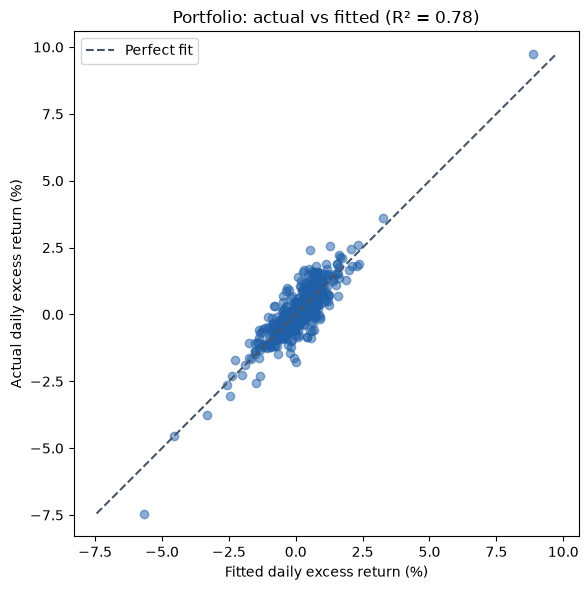

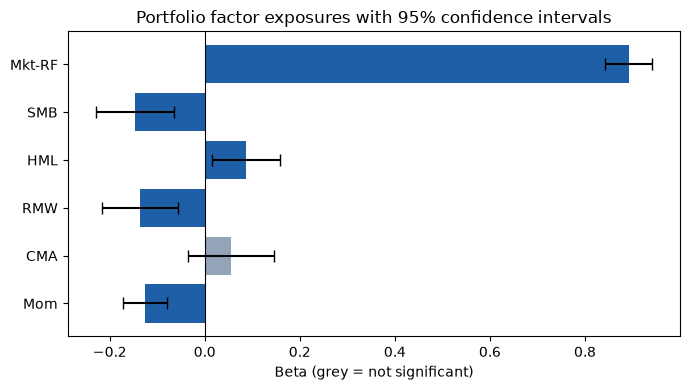

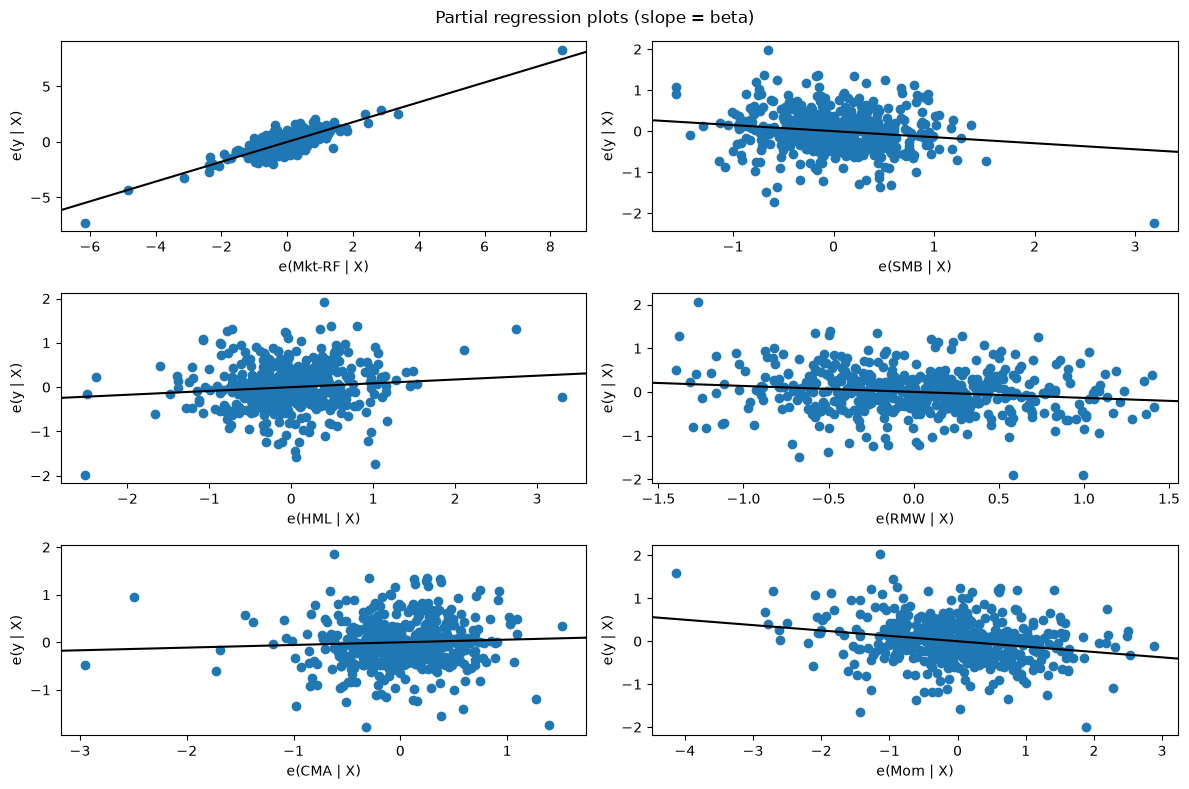

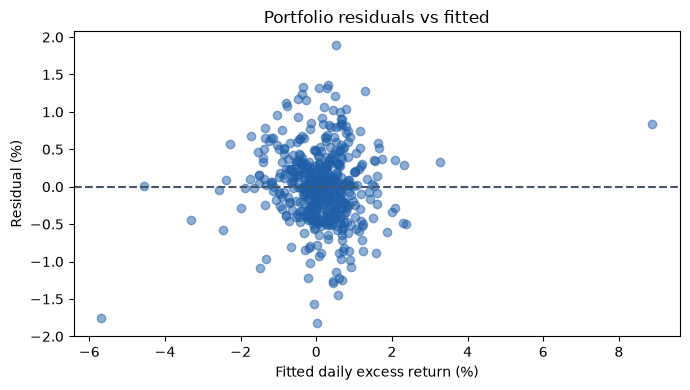

In [6]:
pf = results["PORTFOLIO"]                                  # FF6 regression result for the portfolio

# 1. Actual vs fitted: how close is the model to reality?
fitted = pf.fittedvalues
actual = portfolio_excess.loc[fitted.index]
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(fitted, actual, alpha=0.5, color="#1F5FA8")
lims = [min(fitted.min(), actual.min()), max(fitted.max(), actual.max())]
ax.plot(lims, lims, "--", color="#475569", label="Perfect fit")
ax.set_xlabel("Fitted daily excess return (%)")
ax.set_ylabel("Actual daily excess return (%)")
ax.set_title(f"Portfolio: actual vs fitted (R² = {pf.rsquared:.2f})")
ax.legend()
plt.tight_layout()
plt.show()

# 2. Betas with 95% confidence intervals: which exposures are real?
betas = pf.params[FACTORS]
ci = pf.conf_int().loc[FACTORS]
significant = pf.pvalues[FACTORS] < 0.05
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(FACTORS, betas, color=["#1F5FA8" if s else "#94A3B8" for s in significant],
        xerr=[betas - ci[0], ci[1] - betas], capsize=4)
ax.axvline(0, color="black", linewidth=0.8)
ax.invert_yaxis()                                          # Mkt-RF on top
ax.set_xlabel("Beta (grey = not significant)")
ax.set_title("Portfolio factor exposures with 95% confidence intervals")
plt.tight_layout()
plt.show()

# 3. Partial regression plots: each factor's effect with the other five held constant
fig = plt.figure(figsize=(12, 8))
sm.graphics.plot_partregress_grid(pf, exog_idx=FACTORS, fig=fig)
fig.suptitle("Partial regression plots (slope = beta)")
plt.tight_layout()
plt.show()

# 4. Residuals vs fitted: is anything left unexplained?
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(fitted, pf.resid, alpha=0.5, color="#1F5FA8")
ax.axhline(0, color="#475569", linestyle="--")
ax.set_xlabel("Fitted daily excess return (%)")
ax.set_ylabel("Residual (%)")
ax.set_title("Portfolio residuals vs fitted")
plt.tight_layout()
plt.show()

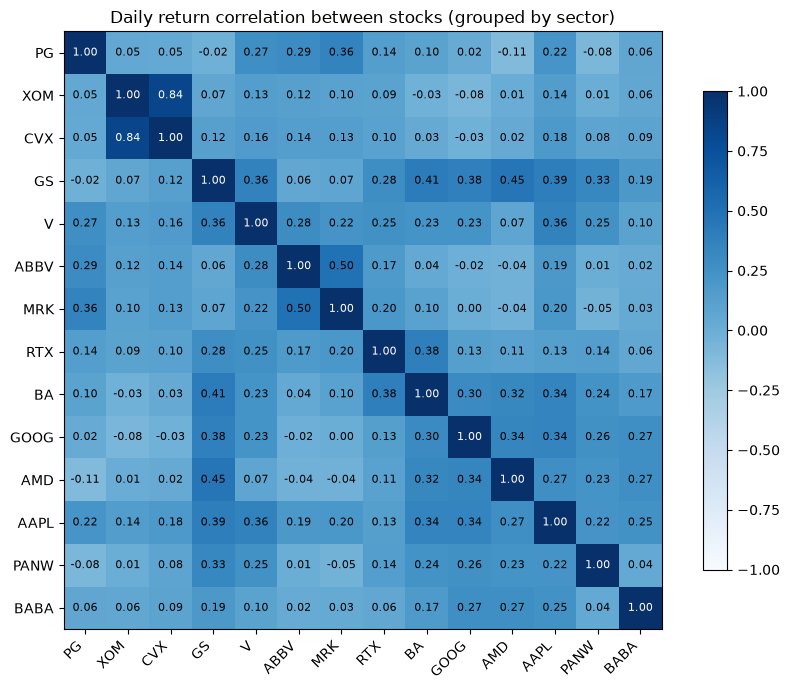

Average pairwise correlation: 0.16
Highest: 0.84   Lowest: -0.11


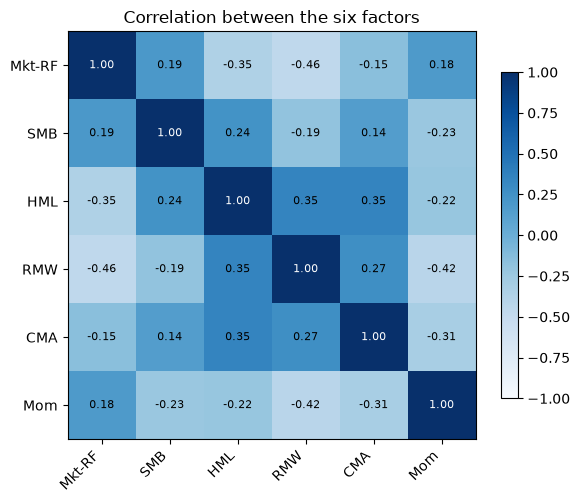

In [7]:
def plot_corr(corr, title, size=(9, 7)):
    """Heatmap of a correlation matrix with the numbers printed in each cell."""
    fig, ax = plt.subplots(figsize=size)
    im = ax.imshow(corr, cmap="Blues", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(corr)), corr.index)
    for i in range(len(corr)):
        for j in range(len(corr)):
            v = corr.iloc[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(v) > 0.6 else "black")
    fig.colorbar(im, ax=ax, shrink=0.8)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

# 1. Correlation between the stocks' daily returns, grouped by sector
tickers = sorted([t for t in results if t != "PORTFOLIO"], key=lambda t: STOCKS[t][1])
stock_corr = data[tickers].corr()
plot_corr(stock_corr, "Daily return correlation between stocks (grouped by sector)")

# Average correlation between different stocks (excludes the 1.0 diagonal)
pairs = stock_corr.values[np.triu_indices(len(tickers), k=1)]
print(f"Average pairwise correlation: {pairs.mean():.2f}")
print(f"Highest: {pairs.max():.2f}   Lowest: {pairs.min():.2f}")

# 2. Correlation between the six factors
factor_corr = data[FACTORS].corr()
plot_corr(factor_corr, "Correlation between the six factors", size=(6, 5))